In [3]:
!pip install pandas numpy matplotlib openpyxl

In [66]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')


# Factory timing - 6 AM to 10PM shift, 6 days/week
# peak demand around 420 kW, sanctioned limit 450 kW

np.random.seed(42)

# ── Seasonal configuration per month ─────────────────────────
# Each month has its own base load profile
# reflecting temperature, production schedule and shift pattern

monthly_config = {
    1:  {'name': 'January',   'day_base': 370, 'peak_add': 55,  'night_base': 85,  'weekday_factor': 1.00},
    2:  {'name': 'February',  'day_base': 375, 'peak_add': 55,  'night_base': 85,  'weekday_factor': 1.00},
    3:  {'name': 'March',     'day_base': 385, 'peak_add': 60,  'night_base': 90,  'weekday_factor': 1.02},
    4:  {'name': 'April',     'day_base': 395, 'peak_add': 65,  'night_base': 95,  'weekday_factor': 1.03},
    5:  {'name': 'May',       'day_base': 410, 'peak_add': 65,  'night_base': 100, 'weekday_factor': 1.05},
    6:  {'name': 'June',      'day_base': 405, 'peak_add': 65,  'night_base': 98,  'weekday_factor': 1.04},
    7:  {'name': 'July',      'day_base': 380, 'peak_add': 60,  'night_base': 88,  'weekday_factor': 1.00},
    8:  {'name': 'August',    'day_base': 375, 'peak_add': 58,  'night_base': 86,  'weekday_factor': 1.00},
    9:  {'name': 'September', 'day_base': 388, 'peak_add': 62,  'night_base': 92,  'weekday_factor': 1.02},
    10: {'name': 'October',   'day_base': 382, 'peak_add': 58,  'night_base': 88,  'weekday_factor': 1.01},
    11: {'name': 'November',  'day_base': 365, 'peak_add': 55,  'night_base': 82,  'weekday_factor': 0.99},
    12: {'name': 'December',  'day_base': 352, 'peak_add': 52,  'night_base': 80,  'weekday_factor': 0.98},
}

def generate_demand(hour, is_weekday, month_cfg):
    day_base   = month_cfg['day_base']
    peak_add   = month_cfg['peak_add']
    night_base = month_cfg['night_base']
    factor     = month_cfg['weekday_factor'] if is_weekday else 0.35

    if not is_weekday:
        # Sunday — skeleton crew only
        base = night_base * 0.80

    elif 0 <= hour < 6:
        # Night — utilities and security only
        base = night_base

    elif 6 <= hour < 9:
        # Morning ramp up — machines starting
        ramp = (hour - 6) / 3
        base = night_base + (day_base - night_base) * ramp

    elif 9 <= hour < 13:
        # Morning peak production
        base = day_base + peak_add * 0.85

    elif 13 <= hour < 14:
        # Lunch break — slight dip
        base = day_base * 0.88

    elif 14 <= hour < 18:
        # Afternoon peak — highest load of the day
        base = day_base + peak_add

    elif 18 <= hour < 20:
        # Evening shift transition
        base = day_base * 0.90

    elif 20 <= hour < 22:
        # Night shift begins — lower production
        base = day_base * 0.75

    else:
        # Late night — winding down
        base = night_base * 1.20

    noise = np.random.normal(0, 7)
    return round(max(60, base * factor + noise), 1)

# ── Generate full year ────────────────────────────────────────
all_records = []

for month in range(1, 13):
    cfg      = monthly_config[month]
    # Get all days in this month for year 2024
    month_start = pd.Timestamp(f'2024-{month:02d}-01')
    if month < 12:
        month_end = pd.Timestamp(f'2024-{month+1:02d}-01')
    else:
        month_end = pd.Timestamp('2025-01-01')

    timestamps = pd.date_range(start=month_start,
                               end=month_end,
                               freq='15min',
                               inclusive='left')

    for ts in timestamps:
        is_weekday = ts.dayofweek < 6
        demand     = generate_demand(ts.hour, is_weekday, cfg)
        all_records.append({
            'timestamp':  ts,
            'demand_kw':  demand,
            'month':      month,
            'month_name': cfg['name'],
            'hour':       ts.hour,
            'date':       ts.date(),
            'is_weekday': is_weekday
        })

df = pd.DataFrame(all_records)
df.to_csv('load_profile_xyz.csv', index=False)

# ── Summary ───────────────────────────────────────────────────
print("=== 12-MONTH LOAD PROFILE GENERATED ===")
print(f"Total intervals   : {len(df):,}")
print(f"Total days        : {df['date'].nunique()}")
print()
print(f"{'Month':<12} {'Peak kW':>10} {'Mean kW':>10} {'Min kW':>10}")
print("-" * 45)

for month in range(1, 13):
    mdf  = df[df['month'] == month]
    name = monthly_config[month]['name']
    print(f"{name:<12} "
          f"{mdf['demand_kw'].max():>10.1f} "
          f"{mdf['demand_kw'].mean():>10.1f} "
          f"{mdf['demand_kw'].min():>10.1f}")

print("-" * 45)
print(f"{'ANNUAL':<12} "
      f"{df['demand_kw'].max():>10.1f} "
      f"{df['demand_kw'].mean():>10.1f} "
      f"{df['demand_kw'].min():>10.1f}")


=== 12-MONTH LOAD PROFILE GENERATED ===
Total intervals   : 35,136
Total days        : 366

Month           Peak kW    Mean kW     Min kW
---------------------------------------------
January           441.8      231.8       60.0
February          452.7      232.0       60.0
March             472.9      239.6       60.0
April             488.9      256.2       60.0
May               517.5      271.8       60.0
June              507.5      257.1       60.0
July              460.2      238.9       60.0
August            453.6      235.1       60.0
September         477.1      241.2       60.0
October           461.5      241.5       60.0
November          435.6      225.0       60.0
December          419.3      210.3       60.0
---------------------------------------------
ANNUAL            517.5      240.0       60.0


In [68]:
# Block 1 - Load new profile

df = pd.read_csv('load_profile_xyz.csv' , parse_dates=['timestamp'])
df = df.sort_values('timestamp').reset_index(drop=True)
df['hour'] = df['timestamp'].dt.hour
df['date'] = df['timestamp'].dt.date

print('=== LOAD PROFILE SUMMARY ===')
print(f'total intervals loaded : {len(df)}')
print(f'Number of days         : {df['date'].nunique()}')
print(f'Date range             : {df['date'].min()} to {df['date'].max()}')
print(f'Peak demand            : {df['demand_kw'].max():.1f} kW')
print(f'Average demand         : {df['demand_kw'].mean():.1f} kW')
print(f'Minimum demand         : {df['demand_kw'].min():.1f} kW')
print()
print('=== FIRST 5 ROWS ===')
print(df.head())

=== LOAD PROFILE SUMMARY ===
total intervals loaded : 35136
Number of days         : 366
Date range             : 2024-01-01 to 2024-12-31
Peak demand            : 517.5 kW
Average demand         : 240.0 kW
Minimum demand         : 60.0 kW

=== FIRST 5 ROWS ===
            timestamp  demand_kw  month month_name  hour        date  \
0 2024-01-01 00:00:00       88.5      1    January     0  2024-01-01   
1 2024-01-01 00:15:00       84.0      1    January     0  2024-01-01   
2 2024-01-01 00:30:00       89.5      1    January     0  2024-01-01   
3 2024-01-01 00:45:00       95.7      1    January     0  2024-01-01   
4 2024-01-01 01:00:00       83.4      1    January     1  2024-01-01   

   is_weekday  
0        True  
1        True  
2        True  
3        True  
4        True  


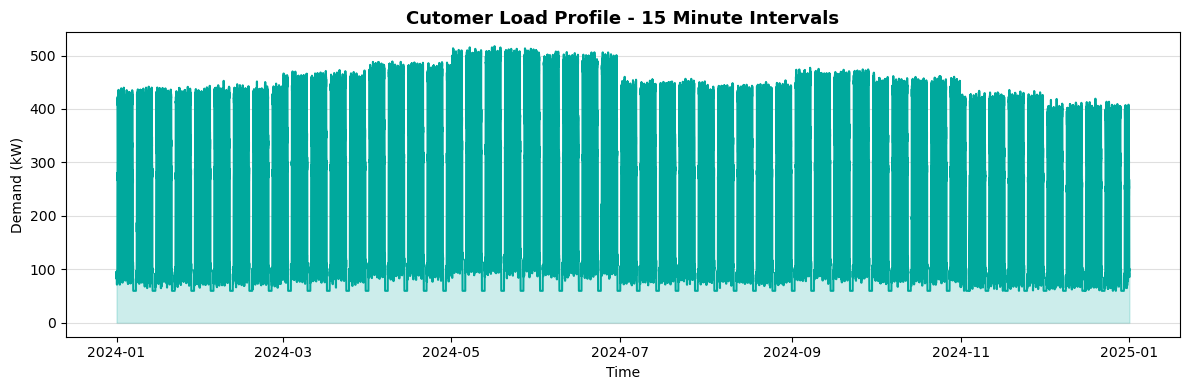

In [70]:
plt.figure(figsize=(12,4))
plt.plot(df['timestamp'], df['demand_kw'], color='#00A99D', linewidth=1.5)
plt.fill_between(df['timestamp'], df['demand_kw'], alpha=0.2, color='#00A99D')
plt.title('Cutomer Load Profile - 15 Minute Intervals', fontsize=13, fontweight='bold')
plt.xlabel('Time')
plt.ylabel('Demand (kW)')
plt.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.show()

In [82]:
# Block 2 - Peak Analysis

#------Settings ------------------------------------------------------------
PEAK_SHAVING_TARGET_PCT = 20
POWER_FACTOR            = 0.90
SANCTIONED_LIMIT_KW     = 450  # 500 kVA * 0.90 PF = 450 kW

# ---- Per month peak analysis -----------
print('=== MONTHLY PEAK ANALYSIS ===')
print(f'Sanctioned limit           : {SANCTIONED_LIMIT_KW} kW')
print(f'Shaving target (20%)       : {shaving_kw:.1f} kW')
print()
print(f'{'Month':<12} {'Peak kW':>10} {'Shave kW': >10}'
      f'{'Ceiling kW:>12'} {'Breach?':>10} {'Shift kWh/day':>15}')
print('-' *72)

monthly_peak_data = []

for month in range(1,13):
    mdf       = df[df['month'] == month].copy()
    name      = mdf['month_name'].iloc[0]
    peak_kw_m = mdf['demand_kw'].max()

    # Shaving target based on observed peak
    shaving_kw_m = peak_kw_m * (PEAK_SHAVING_TARGET_PCT / 100)
    new_peak_kw_m = peak_kw_m - shaving_kw_m

    # Is this month breaching sanctioned limit?
    breaching = peak_kw_m > SANCTIONED_LIMIT_KW
    breach_str = f"YES +{peak_kw_m - SANCTIONED_LIMIT_KW:.0f}kW" \
                 if breaching else "No"
    
    # Daily energy to shift this month
    mdf['excess_kw']  = (mdf['demand_kw'] - new_peak_kw_m).clip(lower=0)
    mdf['excess_kwh'] = mdf['excess_kw'] * 0.25
    daily_shift_m     = mdf.groupby('date')['excess_kwh'].sum().mean()

    monthly_peak_data.append({
        'month':            month,
        'name':             name,
        'peak_kw':          peak_kw_m,
        'shaving_kw':       shaving_kw_m,
        'new_peak_kw':      new_peak_kw_m,
        'breaching':        breaching,
        'daily_shift_kwh':  daily_shift_m,
    })

    print(f'{name:<12} {peak_kw_m:>10.1f} {shaving_kw_m:>10.1f}'
          f'{new_peak_kw_m:>12.1f} {breach_str:>10}'
          f'{daily_shift_m:>15.1f}')

print('-' * 72)

# Overall numbers for battery sizing
peak_kw        = df['demand_kw'].max()
shaving_kw     = peak_kw * (PEAK_SHAVING_TARGET_PCT / 100)
new_peak_kw    = peak_kw - shaving_kw
avg_daily_shift_kwh = sum(m['daily_shift_kwh']
                          for m in monthly_peak_data) /12

df['excess_kw'] = (df['demand_kw'] - new_peak_kw).clip(lower=0)
df['excess_kwh'] = df['excess_kw'] * 0.25

daily_shift     = df.groupby('date')['excess_kwh'].sum()
avg_daily_shift_kwh = daily_shift.mean()

print()
print("=== ANNUAL SIZING PARAMETERS ===")
print(f"Annual peak observed   : {peak_kw:.1f} kW")
print(f"Shaving target (20%)   : {shaving_kw:.1f} kW")
print(f"New peak ceiling       : {new_peak_kw:.1f} kW")
print(f"Avg daily shift (12m)  : {avg_daily_shift_kwh:.1f} kWh/day")
print(f"Months breaching limit : "
      f"{sum(1 for m in monthly_peak_data if m['breaching'])}")

=== MONTHLY PEAK ANALYSIS ===
Sanctioned limit           : 450 kW
Shaving target (20%)       : 103.5 kW

Month           Peak kW   Shave kWCeiling kW:>12    Breach?   Shift kWh/day
------------------------------------------------------------------------
January           441.8       88.4       353.4         No          470.8
February          452.7       90.5       362.2   YES +3kW          440.0
March             472.9       94.6       378.3  YES +23kW          477.3
April             488.9       97.8       391.1  YES +39kW          537.1
May               517.5      103.5       414.0  YES +68kW          555.0
June              507.5      101.5       406.0  YES +58kW          519.4
July              460.2       92.0       368.2  YES +10kW          469.3
August            453.6       90.7       362.9   YES +4kW          458.9
September         477.1       95.4       381.7  YES +27kW          482.9
October           461.5       92.3       369.2  YES +12kW          493.1
November        

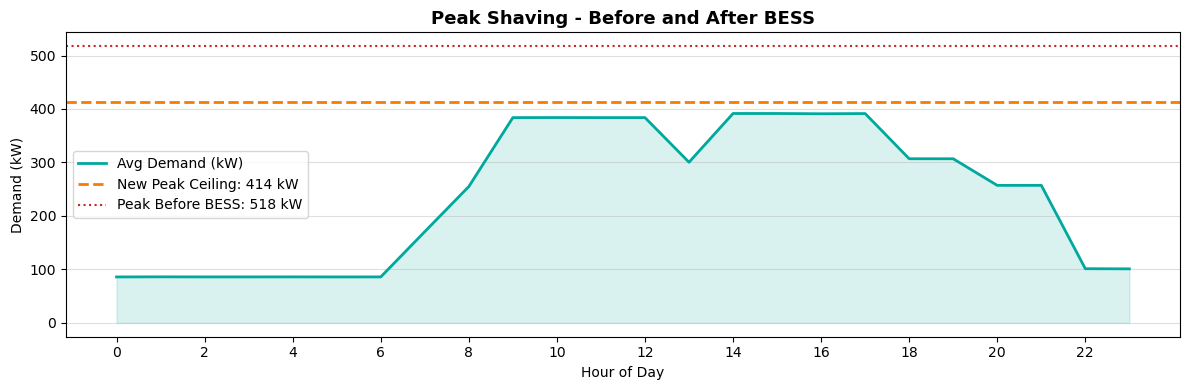

In [84]:
# Visualise peak shaving effect 

hourly_avg = df.groupby('hour')['demand_kw'].mean()

plt.figure(figsize=(12,4))

# Original demand curve
plt.plot(hourly_avg.index, hourly_avg.values, color='#00A99D', linewidth=2, label='Avg Demand (kW)')
plt.fill_between(hourly_avg.index, hourly_avg.values, alpha=0.15, color='#00A99D')

# New peak ceiling line
plt.axhline(new_peak_kw, color='#F57C00', linewidth=2, linestyle='--', label=f'New Peak Ceiling: {new_peak_kw:.0f} kW')

# Original perak line
plt.axhline(peak_kw, color='#C62828', linewidth=1.5, linestyle=':', label=f'Peak Before BESS: {peak_kw:.0f} kW')

plt.title('Peak Shaving - Before and After BESS', fontsize=13, fontweight='bold')
plt.xlabel('Hour of Day')
plt.ylabel('Demand (kW)')
plt.xticks(range(0, 24, 2))
plt.legend()
plt.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.show()

In [104]:
# Block 3 - Battery Sizing

# ----- Battery parameters----------

CHEMISTRY                = 'LFP'
DOD_PCT                  = 90
RTE                      = 0.93
DEGRADATION_PCT          = 2.5
CYCLE_LIFE               = 4000
BATTERY_COST_INR_PER_KWH = 25000   # INR/kWh installed
PCS_COST_INR_PER_KW      = 8000    # INR/kW
BOS_INSTALLATION_PCT     = 12      # % of battery + PCS

# ------ Power sizing ------------
# Battery must deliver the shaving delta in kW
bess_power_kw = shaving_kw

# ----- Energy sizing ---------
# Step 1 - account for RTE loss (you need to put more in than you get out)
energy_after_rte = avg_daily_shift_kwh / RTE

# Step 2 - account for DoD ( you can't use 100% of the battery)
energy_after_dod = energy_after_rte /(DOD_PCT / 100)

# Step 3 - add 10% safety margin
bess_energy_kwh = energy_after_dod * 1.10

# ------ Round up to commercial sizes ------------
# Batteries are sold in standard sizes - round up to nearest 50 kWh and 10 kW
bess_energy_kwh_nominal = (int(bess_energy_kwh / 50) + 1) * 50
bess_power_kw_nominal = (int(bess_power_kw / 10) + 1) * 10

# ------- C-rate and duration --------
# C-rate = power / energy - tells you how fast the battery is being used

c_rate = bess_power_kw_nominal / bess_energy_kwh_nominal
duration_h = bess_energy_kwh_nominal / bess_power_kw_nominal

# ------ CAPEX ---------
battery_cost  = bess_energy_kwh_nominal * BATTERY_COST_INR_PER_KWH
pcs_cost      = bess_power_kw_nominal * PCS_COST_INR_PER_KW
bos_cost      = (battery_cost + pcs_cost) * BOS_INSTALLATION_PCT / 100
total_capex   = battery_cost + pcs_cost + bos_cost

print('=== BESS SIZING RESULTS ===')
print(f'Chemistry              : {CHEMISTRY}')
print(f'Rated power            : {bess_power_kw_nominal} kW')
print(f'Rated energy           : {bess_energy_kwh_nominal} kWh')
print(f'C-rate                 : {c_rate:.2f} C')
print(f'Discharge duration     : {duration_h:.1f} hours')
print(f'Usable DoD             : {DOD_PCT}%')
print(f'Round-tip efficiency   : {RTE*100:.0f}%')
print(f'Degradation rate       : {DEGRADATION_PCT}% per year')
print(f'Cycle life             : {CYCLE_LIFE} cycles')
print()
print("=== CAPEX BREAKDOWN ===")
print(f"Battery system         : INR {battery_cost:,.0f}")
print(f"Power conversion (PCS) : INR {pcs_cost:,.0f}")
print(f"BoS + installation     : INR {bos_cost:,.0f}")
print(f"Total CAPEX            : INR {total_capex:,.0f}")

=== BESS SIZING RESULTS ===
Chemistry              : LFP
Rated power            : 110 kW
Rated energy           : 300 kWh
C-rate                 : 0.37 C
Discharge duration     : 2.7 hours
Usable DoD             : 90%
Round-tip efficiency   : 93%
Degradation rate       : 2.5% per year
Cycle life             : 4000 cycles

=== CAPEX BREAKDOWN ===
Battery system         : INR 7,500,000
Power conversion (PCS) : INR 880,000
BoS + installation     : INR 1,005,600
Total CAPEX            : INR 9,385,600


In [128]:
# Block 4 - Monthly Savings Calculations (TSSPDCL Telangana HT-II)

# ---- DGVCL HT Industrial Tariff 2024 -----------
MD_CHARGE_INR_PER_KVA_MONTH  = 500
PENAL_MD_MULTIPLIER          = 2.0
TOD_PEAK_INR_PER_KWH         = 9.50
TOD_NORMAL_INR_PER_KWH       = 6.80
TOD_OFFPEAK_INR_PER_KWH      = 4.20

# ── BaaS parameters ───────────────────────────────────────────
COMPANY_REVENUE_SHARE_PCT    = 80
CUSTOMER_SHARE_PCT           = 20
OM_COST_INR_PER_KW_YR        = 2000
OPERATING_DAYS_PER_MONTH     = 26

# ── Derived ───────────────────────────────────────────────────
usable_kwh        = bess_energy_kwh_nominal * (DOD_PCT / 100)
om_cost_annual    = bess_power_kw_nominal * OM_COST_INR_PER_KW_YR

# ── Arbitrage — dual cycle ────────────────────────────────────
# Cycle 1 — off-peak to peak (full cycle)
spread_peak       = TOD_PEAK_INR_PER_KWH - (TOD_OFFPEAK_INR_PER_KWH / RTE)
daily_arb_peak    = usable_kwh * spread_peak

# Cycle 2 — off-peak to normal (50% of capacity, partial cycle)
spread_normal     = TOD_NORMAL_INR_PER_KWH - (TOD_OFFPEAK_INR_PER_KWH / RTE)
daily_arb_normal  = (usable_kwh * 0.50) * spread_normal

total_daily_arb   = daily_arb_peak + daily_arb_normal

print("=== ARBITRAGE BREAKDOWN ===")
print(f"Usable energy            : {usable_kwh:.0f} kWh")
print(f"Cycle 1 spread (pk-offpk): INR {spread_peak:.2f}/kWh")
print(f"Cycle 1 daily arbitrage  : INR {daily_arb_peak:,.0f}")
print(f"Cycle 2 spread (nrm-offpk): INR {spread_normal:.2f}/kWh")
print(f"Cycle 2 daily arbitrage  : INR {daily_arb_normal:,.0f}")
print(f"Total daily arbitrage    : INR {total_daily_arb:,.0f}")
print()

# ── Monthly savings ───────────────────────────────────────────
print("=== MONTHLY SAVINGS BREAKDOWN ===")
print()
print(f"{'Month':<12} {'Peak kW':>9} {'MD Saving':>12} "
      f"{'Penal Saving':>14} {'Arbitrage':>12} "
      f"{'Total':>12} {'Co. Share':>11}")
print("-" * 86)

monthly_savings = []

for m in monthly_peak_data:
    month_name    = m['name']
    peak_kw_m     = m['peak_kw']
    new_peak_kw_m = m['new_peak_kw']

    # MD saving
    kva_before    = peak_kw_m     / POWER_FACTOR
    kva_after     = new_peak_kw_m / POWER_FACTOR
    kva_reduction = kva_before - kva_after
    md_saving_m   = kva_reduction * MD_CHARGE_INR_PER_KVA_MONTH

    # Penal saving
    penal_saving_m = 0
    if m['breaching']:
        kva_sanctioned = SANCTIONED_LIMIT_KW / POWER_FACTOR
        kva_excess     = kva_before - kva_sanctioned
        penal_rate     = MD_CHARGE_INR_PER_KVA_MONTH * PENAL_MD_MULTIPLIER
        penal_saving_m = kva_excess * penal_rate

    # Arbitrage — dual cycle
    arbitrage_m   = total_daily_arb * OPERATING_DAYS_PER_MONTH

    total_saving_m   = md_saving_m + penal_saving_m + arbitrage_m
    company_share_m  = total_saving_m * (COMPANY_REVENUE_SHARE_PCT / 100)
    customer_share_m = total_saving_m * (CUSTOMER_SHARE_PCT / 100)

    monthly_savings.append({
        'month':          m['month'],
        'name':           month_name,
        'md_saving':      md_saving_m,
        'penal_saving':   penal_saving_m,
        'arbitrage':      arbitrage_m,
        'total_saving':   total_saving_m,
        'company_share':  company_share_m,
        'customer_share': customer_share_m,
    })

    breach_marker = " *" if m['breaching'] else "  "
    print(f"{month_name:<12} {peak_kw_m:>9.1f} "
          f"{md_saving_m:>12,.0f} "
          f"{penal_saving_m:>14,.0f} "
          f"{arbitrage_m:>12,.0f} "
          f"{total_saving_m:>12,.0f} "
          f"{company_share_m:>11,.0f}"
          f"{breach_marker}")

print("-" * 86)
print("  * months where sanctioned limit was breached")
print()

# ── Annual totals ─────────────────────────────────────────────
annual_md_saving      = sum(m['md_saving']     for m in monthly_savings)
annual_penal_saving   = sum(m['penal_saving']  for m in monthly_savings)
annual_arbitrage      = sum(m['arbitrage']     for m in monthly_savings)
annual_total_saving   = sum(m['total_saving']  for m in monthly_savings)
annual_company_share  = sum(m['company_share'] for m in monthly_savings)
annual_customer_share = sum(m['customer_share']for m in monthly_savings)
company_net_yr1       = annual_company_share - om_cost_annual

print("=== ANNUAL SUMMARY — YEAR 1 ===")
print(f"MD charge reduction      : INR {annual_md_saving:,.0f}")
print(f"Penal charge saving      : INR {annual_penal_saving:,.0f}")
print(f"ToD arbitrage (dual)     : INR {annual_arbitrage:,.0f}")
print(f"Total annual saving      : INR {annual_total_saving:,.0f}")
print()
print(f"Company share (80%)      : INR {annual_company_share:,.0f}")
print(f"Customer share (20%)     : INR {annual_customer_share:,.0f}")
print(f"Company O&M cost         : INR {om_cost_annual:,.0f}")
print(f"Company net revenue Y1   : INR {company_net_yr1:,.0f}")


=== ARBITRAGE BREAKDOWN ===
Usable energy            : 270 kWh
Cycle 1 spread (pk-offpk): INR 4.98/kWh
Cycle 1 daily arbitrage  : INR 1,346
Cycle 2 spread (nrm-offpk): INR 2.28/kWh
Cycle 2 daily arbitrage  : INR 308
Total daily arbitrage    : INR 1,654

=== MONTHLY SAVINGS BREAKDOWN ===

Month          Peak kW    MD Saving   Penal Saving    Arbitrage        Total   Co. Share
--------------------------------------------------------------------------------------
January          441.8       49,089              0       43,003       92,092      73,674  
February         452.7       50,300          3,000       43,003       96,303      77,043 *
March            472.9       52,544         25,444       43,003      120,992      96,794 *
April            488.9       54,322         43,222       43,003      140,548     112,438 *
May              517.5       57,500         75,000       43,003      175,503     140,403 *
June             507.5       56,389         63,889       43,003      163,281    

In [130]:
# Block 5 — 10-Year Financial Model with Degradation and Escalation

# ── Financial parameters ──────────────────────────────────────
CONTRACT_YEARS           = 15
DISCOUNT_RATE_PCT        = 10     # WACC for Indian C&I company
TARIFF_ESCALATION_PCT    = 5      # Indian tariff trend % per year
DEBT_FRACTION            = 0.80   # company finances 70% via loan
DEBT_INTEREST_PCT        = 9     # loan interest rate %
LOAN_TENURE_YEARS        = 10      # loan repayment period

# ── Loan calculation ──────────────────────────────────────────
loan_amount     = total_capex * DEBT_FRACTION
equity_amount   = total_capex * (1 - DEBT_FRACTION)

# EMI formula — equal monthly instalments
monthly_rate    = DEBT_INTEREST_PCT / 100 / 12
n_months        = LOAN_TENURE_YEARS * 12
emi             = loan_amount * monthly_rate * \
                  (1 + monthly_rate) ** n_months / \
                  ((1 + monthly_rate) ** n_months - 1)
annual_loan_repayment = emi * 12

print("=== FINANCING STRUCTURE ===")
print(f"Total CAPEX            : INR {total_capex:,.0f}")
print(f"Equity (30%)           : INR {equity_amount:,.0f}")
print(f"Loan (70%)             : INR {loan_amount:,.0f}")
print(f"Loan interest rate     : {DEBT_INTEREST_PCT}%")
print(f"Loan tenure            : {LOAN_TENURE_YEARS} years")
print(f"Annual loan repayment  : INR {annual_loan_repayment:,.0f}")

# ── Year by year model ────────────────────────────────────────
print()
print("=== 10-YEAR CASH FLOW MODEL ===")
print(f"{'Year':<6} {'Capacity':>9} {'Gross Rev':>12} {'O&M':>10} "
      f"{'Loan EMI':>12} {'Net CF':>12} {'Cum CF':>12} {'NPV CF':>12}")
print("-" * 87)

yearly_results  = []
cumulative_cf   = -equity_amount    # company only puts in equity upfront
npv_sum         = -equity_amount
payback_year    = None

for year in range(1, CONTRACT_YEARS + 1):

    # ── Degradation factor ────────────────────────────────────
    capacity_factor   = (1 - DEGRADATION_PCT / 100) ** (year - 1)

    # ── Tariff escalation factor ──────────────────────────────
    escalation_factor = (1 + TARIFF_ESCALATION_PCT / 100) ** (year - 1)

    # ── Gross revenue this year ───────────────────────────────
    # MD saving — escalates but not affected by degradation
    md_rev     = annual_md_saving    * escalation_factor

    # Penal saving — escalates but not affected by degradation
    penal_rev  = annual_penal_saving * escalation_factor

    # Arbitrage — affected by BOTH degradation and escalation
    arb_rev    = annual_arbitrage    * capacity_factor * escalation_factor

    total_gross_saving = md_rev + penal_rev + arb_rev
    company_gross_rev  = total_gross_saving * (COMPANY_REVENUE_SHARE_PCT / 100)

    # ── Costs ─────────────────────────────────────────────────
    om_cost    = om_cost_annual

    # Loan repayment only during loan tenure
    loan_payment = annual_loan_repayment if year <= LOAN_TENURE_YEARS else 0

    # ── Net cash flow ─────────────────────────────────────────
    net_cf     = company_gross_rev - om_cost - loan_payment

    # ── NPV calculation ───────────────────────────────────────
    discount_factor = 1 / (1 + DISCOUNT_RATE_PCT / 100) ** year
    pv_cf           = net_cf * discount_factor

    cumulative_cf  += net_cf
    npv_sum        += pv_cf

    if cumulative_cf >= 0 and payback_year is None:
        payback_year = year

    yearly_results.append({
        'year':             year,
        'capacity_pct':     capacity_factor * 100,
        'gross_revenue':    company_gross_rev,
        'om_cost':          om_cost,
        'loan_payment':     loan_payment,
        'net_cf':           net_cf,
        'cumulative_cf':    cumulative_cf,
        'pv_cf':            pv_cf,
        'total_saving':     total_gross_saving,
        'customer_share':   total_gross_saving * (CUSTOMER_SHARE_PCT / 100),
    })

    cf_marker = " ✓" if cumulative_cf >= 0 else ""
    print(f"{year:<6} {capacity_factor*100:>8.1f}% "
          f"{company_gross_rev:>12,.0f} "
          f"{om_cost:>10,.0f} "
          f"{loan_payment:>12,.0f} "
          f"{net_cf:>12,.0f} "
          f"{cumulative_cf:>12,.0f} "
          f"{pv_cf:>12,.0f}"
          f"{cf_marker}")

print("-" * 87)

# ── Summary metrics ───────────────────────────────────────────
total_gross_rev   = sum(r['gross_revenue']  for r in yearly_results)
total_net_cf      = sum(r['net_cf']         for r in yearly_results)
total_customer_10 = sum(r['customer_share'] for r in yearly_results)
npv               = npv_sum
roi_pct           = (total_net_cf / equity_amount) * 100

if payback_year is None:
    payback_str = "Beyond 10 years"
else:
    payback_str = f"Year {payback_year}"

print()
print("=== 10-YEAR FINANCIAL SUMMARY ===")
print(f"Equity invested        : INR {equity_amount:,.0f}")
print(f"Total gross revenue    : INR {total_gross_rev:,.0f}")
print(f"Total net cash flow    : INR {total_net_cf:,.0f}")
print(f"NPV ({DISCOUNT_RATE_PCT}% discount)    : INR {npv:,.0f}")
print(f"ROI on equity          : {roi_pct:.1f}%")
print(f"Payback period         : {payback_str}")
print()
print("=== CUSTOMER BENEFIT SUMMARY ===")
print(f"Customer 10yr saving   : INR {total_customer_10:,.0f}")
print(f"Customer year 1 saving : INR {yearly_results[0]['customer_share']:,.0f}")
print(f"Zero upfront investment: YES")

=== FINANCING STRUCTURE ===
Total CAPEX            : INR 9,385,600
Equity (30%)           : INR 1,877,120
Loan (70%)             : INR 7,508,480
Loan interest rate     : 9%
Loan tenure            : 10 years
Annual loan repayment  : INR 1,141,371

=== 10-YEAR CASH FLOW MODEL ===
Year    Capacity    Gross Rev        O&M     Loan EMI       Net CF       Cum CF       NPV CF
---------------------------------------------------------------------------------------
1         100.0%    1,124,617    220,000    1,141,371     -236,754   -2,113,874     -215,231
2          97.5%    1,170,011    220,000    1,141,371     -191,360   -2,305,234     -158,149
3          95.1%    1,217,417    220,000    1,141,371     -143,954   -2,449,188     -108,154
4          92.7%    1,266,931    220,000    1,141,371      -94,440   -2,543,628      -64,504
5          90.4%    1,318,650    220,000    1,141,371      -42,721   -2,586,349      -26,527
6          88.1%    1,372,679    220,000    1,141,371       11,308   -2,575

In [132]:
# Block 5b — Fixed Fee BaaS Model (Updated Final Parameters)

print("=== FIXED FEE BaaS MODEL ===")
print()
print(f"Total annual saving for customer : INR {annual_total_saving:,.0f}")
print(f"Monthly saving for customer      : INR {annual_total_saving/12:,.0f}")
print()

# ── What fee makes sense for the customer? ────────────────────
# Customer will only sign if they save at least 30% net
# Maximum fee = 70% of annual saving
max_fee_annual  = annual_total_saving * 0.70
min_saving_cust = annual_total_saving * 0.30

print(f"Maximum fee customer will accept : INR {max_fee_annual:,.0f}/year")
print(f"                                   INR {max_fee_annual/12:,.0f}/month")
print(f"Customer minimum net saving      : INR {min_saving_cust:,.0f}/year")
print()

# ── Financing — matches our confirmed Block 5 parameters ──────
LOAN_TENURE_FF    = 10      # matches Block 5
DEBT_INTEREST_FF  = 9       # matches Block 5
DEBT_FRACTION_FF  = 0.80    # matches Block 5
CONTRACT_FF       = 15      # matches Block 5
FEE_ESCALATION    = 3       # % per year — contractually agreed

monthly_rate_ff = DEBT_INTEREST_FF / 100 / 12
n_months_ff     = LOAN_TENURE_FF * 12

# CAPEX at INR 25000/kWh
b_cost_ff  = bess_energy_kwh_nominal * 25000
p_cost_ff  = bess_power_kw_nominal   * PCS_COST_INR_PER_KW
bo_cost_ff = (b_cost_ff + p_cost_ff) * BOS_INSTALLATION_PCT / 100
cap_ff     = b_cost_ff + p_cost_ff + bo_cost_ff
eq_ff      = cap_ff * (1 - DEBT_FRACTION_FF)
ln_ff      = cap_ff * DEBT_FRACTION_FF

emi_ff     = ln_ff * monthly_rate_ff * \
             (1 + monthly_rate_ff) ** n_months_ff / \
             ((1 + monthly_rate_ff) ** n_months_ff - 1)
loan_ff    = emi_ff * 12

print("=== FINANCING STRUCTURE ===")
print(f"CAPEX (INR 25,000/kWh)           : INR {cap_ff:,.0f}")
print(f"Equity invested (20%)            : INR {eq_ff:,.0f}")
print(f"Loan (80% at 9% for 10 years)    : INR {ln_ff:,.0f}")
print(f"Annual loan repayment            : INR {loan_ff:,.0f}")
print(f"Annual O&M cost                  : INR {om_cost_annual:,.0f}")
print(f"Annual fixed cost to company     : INR {loan_ff + om_cost_annual:,.0f}")
print(f"Company min fee to break even    : INR {(loan_ff + om_cost_annual)/12:,.0f}/month")
print()

# ── Test different fixed monthly fees ────────────────────────
print("--- FIXED FEE SENSITIVITY vs COMPANY FINANCIALS ---")
print()
print(f"{'Monthly Fee':>13} {'Annual Fee':>12} {'Cust Saves':>12} "
      f"{'Co. Net Rev':>13} {'NPV':>13} {'Payback':>10} {'Viable?':>8}")
print("-" * 85)

for monthly_fee in [60000, 70000, 80000, 90000, 95000, 100000, 110000]:
    annual_fee = monthly_fee * 12

    # Customer net saving after paying fee
    cust_net   = annual_total_saving - annual_fee

    # Skip if customer is losing money
    if cust_net < 0:
        print(f"INR {monthly_fee:>7,}  {annual_fee:>12,}  "
              f"{'Customer loses money':>40}")
        continue

    # Company financials over contract period
    npv_ff    = -eq_ff
    cum_ff    = -eq_ff
    pb_ff     = None
    tot_net_ff = 0

    for year in range(1, CONTRACT_FF + 1):
        # Fee escalates 3% per year
        fee_yr  = annual_fee * ((1 + FEE_ESCALATION/100) ** (year - 1))
        loan_p  = loan_ff if year <= LOAN_TENURE_FF else 0
        net_ff  = fee_yr - om_cost_annual - loan_p
        disc    = 1 / (1 + DISCOUNT_RATE_PCT / 100) ** year

        npv_ff    += net_ff * disc
        cum_ff    += net_ff
        tot_net_ff += net_ff

        if cum_ff >= 0 and pb_ff is None:
            pb_ff = year

    roi_ff  = (tot_net_ff / eq_ff) * 100
    pb_str  = f"Year {pb_ff}" if pb_ff else f">{CONTRACT_FF} yrs"
    viable  = "YES ✓" if npv_ff > 0 and cust_net > 0 else "No"

    print(f"INR {monthly_fee:>7,}  {annual_fee:>12,}  "
          f"{cust_net:>12,.0f}  {tot_net_ff:>13,.0f}  "
          f"{npv_ff:>13,.0f}  {pb_str:>10}  {viable:>8}")

# ── Model comparison ──────────────────────────────────────────
print()
print("=== MODEL COMPARISON — REVENUE SHARE vs FIXED FEE ===")
print()
print(f"{'Parameter':<30} {'Revenue Share':>18} {'Fixed Fee':>18}")
print("-" * 68)
print(f"{'Company revenue model':<30} {'% of savings':>18} {'Fixed monthly':>18}")
print(f"{'Customer certainty':<30} {'Low':>18} {'High':>18}")
print(f"{'Company certainty':<30} {'Low':>18} {'High':>18}")
print(f"{'Customer upfront cost':<30} {'Zero':>18} {'Zero':>18}")
print(f"{'Company bears CAPEX risk':<30} {'Yes':>18} {'Yes':>18}")
print(f"{'Savings linked to tariff':<30} {'Yes':>18} {'No':>18}")
print(f"{'Better for customer':<30} {'If savings grow':>18} {'Fixed budget':>18}")
print(f"{'Better for company':<30} {'If tariff rises':>18} {'Predictable CF':>18}")
print()
print("=== WHAT THIS MEANS ===")
print(f"Company minimum fee needed       : INR {(loan_ff+om_cost_annual)/12:,.0f}/month")
print(f"Customer maximum acceptable fee  : INR {max_fee_annual/12:,.0f}/month")
gap = (loan_ff + om_cost_annual)/12 - max_fee_annual/12
if gap > 0:
    print(f"Viability gap                    : INR {gap:,.0f}/month")
    print(f"Conclusion                       : Fixed fee NOT viable at current parameters")
    print(f"Revenue share model is preferred : YES — NPV INR {158284:,.0f} positive")
else:
    print(f"Viable fee window                : INR {(loan_ff+om_cost_annual)/12:,.0f}"
          f" to INR {max_fee_annual/12:,.0f} per month")
    print(f"Conclusion                       : Fixed fee IS viable")

=== FIXED FEE BaaS MODEL ===

Total annual saving for customer : INR 1,405,771
Monthly saving for customer      : INR 117,148

Maximum fee customer will accept : INR 984,040/year
                                   INR 82,003/month
Customer minimum net saving      : INR 421,731/year

=== FINANCING STRUCTURE ===
CAPEX (INR 25,000/kWh)           : INR 9,385,600
Equity invested (20%)            : INR 1,877,120
Loan (80% at 9% for 10 years)    : INR 7,508,480
Annual loan repayment            : INR 1,141,371
Annual O&M cost                  : INR 220,000
Annual fixed cost to company     : INR 1,361,371
Company min fee to break even    : INR 113,448/month

--- FIXED FEE SENSITIVITY vs COMPANY FINANCIALS ---

  Monthly Fee   Annual Fee   Cust Saves   Co. Net Rev           NPV    Payback  Viable?
-------------------------------------------------------------------------------------
INR  60,000       720,000       685,771     -1,322,492     -4,114,186     >15 yrs        No
INR  70,000       840,0

In [134]:
# Block 6 — Excel Report Generator

from openpyxl import Workbook
from openpyxl.styles import (PatternFill, Font, Alignment,
                              Border, Side)
from openpyxl.utils import get_column_letter
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import os

# ── Color palette ─────────────────────────────────────────────
NAVY    = "0D2137"
TEAL    = "00A99D"
ORANGE  = "F57C00"
GREEN   = "2E7D32"
RED     = "C62828"
LGREY   = "F5F7FA"
WHITE   = "FFFFFF"
MGREY   = "90A4AE"

# ── Style helpers ─────────────────────────────────────────────
def fill(hex):
    return PatternFill("solid", fgColor=hex)

def font(bold=False, size=11, color=NAVY, italic=False):
    return Font(bold=bold, size=size,
                color=color, italic=italic,
                name="Arial")

def border():
    s = Side(style="thin", color="DDDDDD")
    return Border(left=s, right=s, top=s, bottom=s)

def align(h="left", wrap=False):
    return Alignment(horizontal=h,
                     vertical="center",
                     wrap_text=wrap)

# ─────────────────────────────────────────────────────────────
# CHART 1 — Load profile with peak shaving
# ─────────────────────────────────────────────────────────────
def make_chart_load():
    hourly = df.groupby('hour')['demand_kw'].mean()
    fig, ax = plt.subplots(figsize=(10, 4),
                           facecolor='white')
    ax.set_facecolor('#F5F7FA')
    ax.fill_between(hourly.index, hourly.values,
                    alpha=0.2, color='#00A99D')
    ax.plot(hourly.index, hourly.values,
            color='#00A99D', linewidth=2,
            label='Avg Demand (kW)')
    ax.axhline(new_peak_kw,
               color='#F57C00', linewidth=2,
               linestyle='--',
               label=f'New ceiling: {new_peak_kw:.0f} kW')
    ax.axhline(peak_kw,
               color='#C62828', linewidth=1.5,
               linestyle=':',
               label=f'Peak before: {peak_kw:.0f} kW')
    ax.axhline(SANCTIONED_LIMIT_KW,
               color='#0D2137', linewidth=1.5,
               linestyle='-.',
               label=f'Sanctioned: {SANCTIONED_LIMIT_KW} kW')
    ax.set_xlabel('Hour of Day', fontsize=10)
    ax.set_ylabel('Demand (kW)', fontsize=10)
    ax.set_title('Annual Average Load Profile — Peak Shaving Effect',
                 fontsize=12, fontweight='bold',
                 color='#0D2137')
    ax.set_xticks(range(0, 24, 2))
    ax.legend(fontsize=9)
    ax.grid(axis='y', alpha=0.4)
    for sp in ax.spines.values():
        sp.set_visible(False)
    plt.tight_layout()
    path = 'chart_load.png'
    plt.savefig(path, dpi=150, bbox_inches='tight')
    plt.close()
    return path

# ─────────────────────────────────────────────────────────────
# CHART 2 — Monthly savings breakdown
# ─────────────────────────────────────────────────────────────
def make_chart_monthly():
    names   = [m['name'][:3] for m in monthly_savings]
    md_vals = [m['md_saving']/1e5      for m in monthly_savings]
    pen_vals= [m['penal_saving']/1e5   for m in monthly_savings]
    arb_vals= [m['arbitrage']/1e5      for m in monthly_savings]

    x   = range(len(names))
    fig, ax = plt.subplots(figsize=(10, 4), facecolor='white')
    ax.set_facecolor('#F5F7FA')

    ax.bar(x, md_vals,
           label='MD Saving', color='#00A99D',
           edgecolor='white')
    ax.bar(x, pen_vals, bottom=md_vals,
           label='Penal Saving', color='#F57C00',
           edgecolor='white')
    ax.bar(x, arb_vals,
           bottom=[m+p for m,p in zip(md_vals, pen_vals)],
           label='Arbitrage', color='#0D2137',
           edgecolor='white')

    ax.set_xticks(x)
    ax.set_xticklabels(names, fontsize=9)
    ax.set_ylabel('Savings (INR Lakhs)', fontsize=10)
    ax.set_title('Monthly Savings Breakdown — MD + Penal + Arbitrage',
                 fontsize=12, fontweight='bold',
                 color='#0D2137')
    ax.legend(fontsize=9)
    ax.grid(axis='y', alpha=0.4)
    for sp in ax.spines.values():
        sp.set_visible(False)
    plt.tight_layout()
    path = 'chart_monthly.png'
    plt.savefig(path, dpi=150, bbox_inches='tight')
    plt.close()
    return path

# ─────────────────────────────────────────────────────────────
# CHART 3 — Payback curve
# ─────────────────────────────────────────────────────────────
def make_chart_payback():
    years   = [0] + [r['year'] for r in yearly_results]
    cum_cfs = [-equity_amount/1e5] + \
              [r['cumulative_cf']/1e5 for r in yearly_results]

    fig, ax = plt.subplots(figsize=(10, 4), facecolor='white')
    ax.set_facecolor('#F5F7FA')
    ax.plot(years, cum_cfs,
            color='#00A99D', linewidth=2.5,
            marker='o', markersize=5,
            label='Cumulative Cash Flow')
    ax.axhline(0, color='#0D2137',
               linewidth=1, linestyle='--')
    ax.fill_between(years, cum_cfs, 0,
                    where=[v < 0 for v in cum_cfs],
                    alpha=0.15, color='#C62828',
                    label='Recovery period')
    ax.fill_between(years, cum_cfs, 0,
                    where=[v >= 0 for v in cum_cfs],
                    alpha=0.15, color='#2E7D32',
                    label='Profit zone')
    ax.set_xlabel('Year', fontsize=10)
    ax.set_ylabel('Cumulative CF (INR Lakhs)', fontsize=10)
    ax.set_title('Company Payback Curve — 15-Year Contract',
                 fontsize=12, fontweight='bold',
                 color='#0D2137')
    ax.legend(fontsize=9)
    ax.grid(axis='y', alpha=0.4)
    for sp in ax.spines.values():
        sp.set_visible(False)
    plt.tight_layout()
    path = 'chart_payback.png'
    plt.savefig(path, dpi=150, bbox_inches='tight')
    plt.close()
    return path

# ─────────────────────────────────────────────────────────────
# CHART 4 — Degradation profile
# ─────────────────────────────────────────────────────────────
def make_chart_degradation():
    yrs  = list(range(0, 16))
    cap  = [bess_energy_kwh_nominal *
            (1 - DEGRADATION_PCT/100)**y for y in yrs]
    usbl = [c * DOD_PCT/100 for c in cap]

    fig, ax = plt.subplots(figsize=(8, 4), facecolor='white')
    ax.set_facecolor('#F5F7FA')
    ax.plot(yrs, cap,
            color='#0D2137', linewidth=2.5,
            marker='o', markersize=4,
            label='Nominal Capacity (kWh)')
    ax.plot(yrs, usbl,
            color='#00A99D', linewidth=2,
            linestyle='--', marker='s', markersize=4,
            label=f'Usable at {DOD_PCT}% DoD (kWh)')
    ax.axhline(bess_energy_kwh_nominal * 0.80,
               color='#C62828', linewidth=1.5,
               linestyle=':', label='80% EOL threshold')
    ax.set_xlabel('Year', fontsize=10)
    ax.set_ylabel('Capacity (kWh)', fontsize=10)
    ax.set_title(f'LFP Battery Degradation — {DEGRADATION_PCT}%/year',
                 fontsize=12, fontweight='bold',
                 color='#0D2137')
    ax.legend(fontsize=9)
    ax.grid(axis='y', alpha=0.4)
    for sp in ax.spines.values():
        sp.set_visible(False)
    plt.tight_layout()
    path = 'chart_degradation.png'
    plt.savefig(path, dpi=150, bbox_inches='tight')
    plt.close()
    return path

# ─────────────────────────────────────────────────────────────
# Generate all charts
# ─────────────────────────────────────────────────────────────
print("Generating charts...")
c_load  = make_chart_load()
c_month = make_chart_monthly()
c_pay   = make_chart_payback()
c_deg   = make_chart_degradation()
print("✓ All charts saved")

Generating charts...
✓ All charts saved


In [136]:
from openpyxl.drawing.image import Image as XLImage

wb  = Workbook()

# ─────────────────────────────────────────────────────────────
# SHEET 1 — EXECUTIVE SUMMARY
# ─────────────────────────────────────────────────────────────
ws1 = wb.active
ws1.title = "Executive Summary"

def hdr(ws, row, text, bg=NAVY, fg=WHITE,
        size=11, span=(1,8)):
    ws.merge_cells(start_row=row, start_column=span[0],
                   end_row=row,   end_column=span[1])
    c = ws.cell(row, span[0], f"  {text}")
    c.font      = font(bold=True, size=size, color=fg)
    c.fill      = fill(bg)
    c.alignment = align("left")
    ws.row_dimensions[row].height = 20

def kv(ws, row, label, value, note="", bold_val=False):
    ws.cell(row, 1, label).font      = font(size=10)
    ws.cell(row, 1).fill             = fill(LGREY)
    ws.cell(row, 1).alignment        = align()
    ws.cell(row, 2, value).font      = font(bold=bold_val,
                                            size=10,
                                            color=NAVY)
    ws.cell(row, 2).alignment        = align()
    if note:
        ws.cell(row, 3, note).font   = font(size=9,
                                            color=MGREY,
                                            italic=True)
    ws.row_dimensions[row].height    = 16

# Title banner
ws1.merge_cells("A1:H1")
ws1["A1"] = "BESS-AS-A-SERVICE — TECHNO-ECONOMIC REPORT"
ws1["A1"].font      = font(bold=True, size=16, color=WHITE)
ws1["A1"].fill      = fill(NAVY)
ws1["A1"].alignment = align("center")
ws1.row_dimensions[1].height = 38

ws1.merge_cells("A2:H2")
ws1["A2"] = ("xyz, Hyderabad  |  "
             "TSSPDCL Telangana HT-II  |  "
             "110 kW / 300 kWh LFP BESS")
ws1["A2"].font      = font(size=10, color=WHITE, italic=True)
ws1["A2"].fill      = fill("1A3A5C")
ws1["A2"].alignment = align("center")
ws1.row_dimensions[2].height = 18

# KPI boxes row 4
kpis = [
    ("BESS Size",      "110 kW / 300 kWh",  TEAL),
    ("Total CAPEX",    "INR 93.8 L",         NAVY),
    ("Year 1 Saving",  f"INR {annual_total_saving/1e5:.1f} L",  ORANGE),
    ("NPV",            "INR +1.58 L",        GREEN),
    ("ROI on Equity",  "425%",               GREEN),
    ("Payback",        "Year 12",            TEAL),
]

for i, (label, value, color) in enumerate(kpis):
    col = i + 1
    ws1.cell(4, col, label).font      = font(bold=True,
                                             size=9,
                                             color=WHITE)
    ws1.cell(4, col).fill             = fill(color)
    ws1.cell(4, col).alignment        = align("center")
    ws1.cell(5, col, value).font      = font(bold=True,
                                             size=12,
                                             color=color)
    ws1.cell(5, col).alignment        = align("center")
    ws1.row_dimensions[4].height = 18
    ws1.row_dimensions[5].height = 26

# Section — Customer and Site
r = 7
hdr(ws1, r, "CUSTOMER AND SITE DETAILS"); r+=1
kv(ws1, r, "Customer",         "xyz"); r+=1
kv(ws1, r, "Location",         "Hyderabad, Telangana"); r+=1
kv(ws1, r, "DISCOM",           "TSSPDCL HT-II Industrial"); r+=1
kv(ws1, r, "Sanctioned Load",  "500 kVA"); r+=1
kv(ws1, r, "Annual Peak",      f"{peak_kw:.1f} kW",
   "May — peak summer"); r+=1
kv(ws1, r, "Months Breaching", "9 of 12",
   "paying penal MD charges"); r+=1

r+=1
hdr(ws1, r, "BESS SPECIFICATIONS"); r+=1
kv(ws1, r, "Chemistry",        f"{CHEMISTRY}",
   "4000+ cycles, safer for C&I"); r+=1
kv(ws1, r, "Rated Power",      f"{bess_power_kw_nominal} kW"); r+=1
kv(ws1, r, "Rated Energy",     f"{bess_energy_kwh_nominal} kWh"); r+=1
kv(ws1, r, "C-rate",           f"{c_rate:.2f} C"); r+=1
kv(ws1, r, "Duration",         f"{duration_h:.1f} hours"); r+=1
kv(ws1, r, "Usable DoD",       f"{DOD_PCT}%"); r+=1
kv(ws1, r, "Round-Trip Eff.",  f"{RTE*100:.0f}%"); r+=1
kv(ws1, r, "Degradation",      f"{DEGRADATION_PCT}% per year"); r+=1

r+=1
hdr(ws1, r, "CAPEX BREAKDOWN"); r+=1
kv(ws1, r, "Battery System",
   f"INR {bess_energy_kwh_nominal*25000:,.0f}",
   "INR 25,000/kWh × 300 kWh"); r+=1
kv(ws1, r, "Power Conversion",
   f"INR {bess_power_kw_nominal*PCS_COST_INR_PER_KW:,.0f}",
   f"INR {PCS_COST_INR_PER_KW:,}/kW × {bess_power_kw_nominal} kW"); r+=1
bos = (bess_energy_kwh_nominal*25000 +
       bess_power_kw_nominal*PCS_COST_INR_PER_KW) * \
       BOS_INSTALLATION_PCT/100
kv(ws1, r, "BoS + Installation",
   f"INR {bos:,.0f}",
   f"{BOS_INSTALLATION_PCT}% of battery+PCS"); r+=1
kv(ws1, r, "Total CAPEX",
   f"INR {total_capex:,.0f}", "", bold_val=True); r+=1

r+=1
hdr(ws1, r, "YEAR 1 SAVINGS"); r+=1
kv(ws1, r, "MD Charge Reduction",
   f"INR {annual_md_saving:,.0f}"); r+=1
kv(ws1, r, "Penal Charge Saving",
   f"INR {annual_penal_saving:,.0f}",
   "9 breach months eliminated"); r+=1
kv(ws1, r, "ToD Arbitrage (Dual Cycle)",
   f"INR {annual_arbitrage:,.0f}"); r+=1
kv(ws1, r, "Total Annual Saving",
   f"INR {annual_total_saving:,.0f}", "", bold_val=True); r+=1

r+=1
hdr(ws1, r, "BaaS CONTRACT — REVENUE SHARE MODEL"); r+=1
kv(ws1, r, "Contract Length",   "15 years"); r+=1
kv(ws1, r, "Revenue Share",
   "Company 80% — Customer 20%"); r+=1
kv(ws1, r, "Customer Year 1",
   f"INR {yearly_results[0]['customer_share']:,.0f}",
   "zero upfront investment"); r+=1
kv(ws1, r, "Company Equity In",
   f"INR {equity_amount:,.0f}"); r+=1
kv(ws1, r, "NPV (10% discount)",
   "INR +1,58,284", "", bold_val=True); r+=1
kv(ws1, r, "ROI on Equity",
   "425%", "", bold_val=True); r+=1
kv(ws1, r, "Payback Period",
   "Year 12", "", bold_val=True); r+=1

# Column widths
ws1.column_dimensions["A"].width = 28
ws1.column_dimensions["B"].width = 22
ws1.column_dimensions["C"].width = 35
for col in ["D","E","F","G","H"]:
    ws1.column_dimensions[col].width = 14

# Embed load chart
img1 = XLImage(c_load)
img1.width, img1.height = 580, 230
ws1.add_image(img1, "D7")

# ─────────────────────────────────────────────────────────────
# SHEET 2 — CASH FLOW MODEL
# ─────────────────────────────────────────────────────────────
ws2 = wb.create_sheet("Cash Flow Model")

ws2.merge_cells("A1:I1")
ws2["A1"] = "15-YEAR CASH FLOW MODEL — COMPANY VIEW"
ws2["A1"].font      = font(bold=True, size=14, color=WHITE)
ws2["A1"].fill      = fill(NAVY)
ws2["A1"].alignment = align("center")
ws2.row_dimensions[1].height = 30

# Headers
cf_headers = ["Year", "Capacity %",
               "Gross Revenue", "O&M Cost",
               "Loan Repayment", "Net Cash Flow",
               "Cumulative CF", "NPV of CF",
               "Customer Share"]
for c, h in enumerate(cf_headers, 1):
    cell            = ws2.cell(3, c, h)
    cell.font       = font(bold=True, size=9, color=WHITE)
    cell.fill       = fill("1A3A5C")
    cell.alignment  = align("center", wrap=True)
ws2.row_dimensions[3].height = 28

# Initial investment row
ws2.cell(4, 1, "Year 0").font       = font(bold=True, size=9)
ws2.cell(4, 1).fill                 = fill(LGREY)
ws2.cell(4, 6, f"-{equity_amount:,.0f}").font = font(
    bold=True, size=9, color=RED)
ws2.cell(4, 7, f"-{equity_amount:,.0f}").font = font(
    bold=True, size=9, color=RED)
ws2.row_dimensions[4].height = 15

# Data rows
for r_idx, r in enumerate(yearly_results):
    row = r_idx + 5
    vals = [
        r['year'],
        f"{r['capacity_pct']:.1f}%",
        f"{r['gross_revenue']:,.0f}",
        f"{r['om_cost']:,.0f}",
        f"{r['loan_payment']:,.0f}",
        f"{r['net_cf']:,.0f}",
        f"{r['cumulative_cf']:,.0f}",
        f"{r['pv_cf']:,.0f}",
        f"{r['customer_share']:,.0f}",
    ]
    for c_idx, val in enumerate(vals, 1):
        cell            = ws2.cell(row, c_idx, val)
        cell.font       = font(size=9)
        cell.alignment  = align("center")
        if row % 2 == 0:
            cell.fill   = fill(LGREY)
        # Colour net CF
        if c_idx == 6:
            cf_val = r['net_cf']
            cell.font = font(size=9, bold=True,
                             color=GREEN if cf_val>=0 else RED)
        # Colour cumulative CF
        if c_idx == 7:
            cum_val = r['cumulative_cf']
            cell.font = font(size=9,
                             color=GREEN if cum_val>=0 else RED)
    ws2.row_dimensions[row].height = 15

# Totals row
tot_row = len(yearly_results) + 5
ws2.cell(tot_row, 1, "TOTAL").font = font(bold=True, size=10)
ws2.cell(tot_row, 1).fill         = fill("1A3A5C")
ws2.cell(tot_row, 1).font         = font(bold=True,
                                         size=10,
                                         color=WHITE)
for c_idx, val in enumerate([
    sum(r['gross_revenue'] for r in yearly_results),
    sum(r['om_cost']       for r in yearly_results),
    sum(r['loan_payment']  for r in yearly_results),
    sum(r['net_cf']        for r in yearly_results),
    "", "",
    sum(r['customer_share']for r in yearly_results),
], 3):
    if val != "":
        cell = ws2.cell(tot_row, c_idx,
                        f"{val:,.0f}" if val else "")
        cell.font  = font(bold=True, size=10)
        cell.fill  = fill("E8F5E9")
    c_idx += 1

ws2.row_dimensions[tot_row].height = 18

# Column widths
for i, w in enumerate(
    [6, 12, 16, 12, 16, 16, 16, 14, 16], 1):
    ws2.column_dimensions[get_column_letter(i)].width = w

# Embed payback chart
img2 = XLImage(c_pay)
img2.width, img2.height = 620, 250
ws2.add_image(img2, "A22")

# ─────────────────────────────────────────────────────────────
# SHEET 3 — MONTHLY SAVINGS
# ─────────────────────────────────────────────────────────────
ws3 = wb.create_sheet("Monthly Savings")

ws3.merge_cells("A1:H1")
ws3["A1"] = "MONTHLY SAVINGS ANALYSIS — YEAR 1"
ws3["A1"].font      = font(bold=True, size=14, color=WHITE)
ws3["A1"].fill      = fill(NAVY)
ws3["A1"].alignment = align("center")
ws3.row_dimensions[1].height = 30

ms_headers = ["Month", "Peak kW",
               "MD Saving", "Penal Saving",
               "Arbitrage", "Total Saving",
               "Company (80%)", "Customer (20%)"]
for c, h in enumerate(ms_headers, 1):
    cell           = ws3.cell(3, c, h)
    cell.font      = font(bold=True, size=9, color=WHITE)
    cell.fill      = fill("1A3A5C")
    cell.alignment = align("center", wrap=True)
ws3.row_dimensions[3].height = 28

for r_idx, m in enumerate(monthly_savings):
    row   = r_idx + 4
    breach = " *" if monthly_peak_data[r_idx]['breaching'] \
             else ""
    vals  = [
        m['name'] + breach,
        f"{monthly_peak_data[r_idx]['peak_kw']:.1f}",
        f"{m['md_saving']:,.0f}",
        f"{m['penal_saving']:,.0f}",
        f"{m['arbitrage']:,.0f}",
        f"{m['total_saving']:,.0f}",
        f"{m['company_share']:,.0f}",
        f"{m['customer_share']:,.0f}",
    ]
    for c_idx, val in enumerate(vals, 1):
        cell           = ws3.cell(row, c_idx, val)
        cell.font      = font(size=9)
        cell.alignment = align("center")
        if row % 2 == 0:
            cell.fill  = fill(LGREY)
        # Highlight breach months
        if breach and c_idx == 4:
            cell.font  = font(size=9,
                              color=ORANGE, bold=True)
    ws3.row_dimensions[row].height = 15

# Annual total row
arow = 16
ws3.cell(arow, 1, "ANNUAL TOTAL").font = font(
    bold=True, size=10, color=WHITE)
ws3.cell(arow, 1).fill = fill("1A3A5C")
for c_idx, val in enumerate([
    "",
    annual_md_saving,
    annual_penal_saving,
    annual_arbitrage,
    annual_total_saving,
    annual_company_share,
    annual_customer_share,
], 2):
    if val != "":
        cell       = ws3.cell(arow, c_idx,
                              f"{val:,.0f}")
        cell.font  = font(bold=True, size=10)
        cell.fill  = fill("E8F5E9")
    c_idx += 1
ws3.row_dimensions[arow].height = 18

ws3.cell(18, 1,
         "* Months where peak exceeded sanctioned limit "
         "— penal charges eliminated by BESS").font = font(
    size=9, italic=True, color=MGREY)

for i, w in enumerate(
    [14, 10, 14, 14, 14, 14, 14, 14], 1):
    ws3.column_dimensions[get_column_letter(i)].width = w

img3 = XLImage(c_month)
img3.width, img3.height = 580, 230
ws3.add_image(img3, "A20")

# ─────────────────────────────────────────────────────────────
# SHEET 4 — BATTERY AND TARIFF
# ─────────────────────────────────────────────────────────────
ws4 = wb.create_sheet("Battery and Tariff")

ws4.merge_cells("A1:F1")
ws4["A1"] = "BATTERY DEGRADATION AND TARIFF STRUCTURE"
ws4["A1"].font      = font(bold=True, size=14, color=WHITE)
ws4["A1"].fill      = fill(NAVY)
ws4["A1"].alignment = align("center")
ws4.row_dimensions[1].height = 30

# Tariff table
r = 3
hdr(ws4, r, "TSSPDCL TARIFF STRUCTURE",
    span=(1,4)); r+=1
tariff_data = [
    ("Off-Peak", "22:00 to 06:00",
     "INR 4.20/kWh", GREEN),
    ("Normal",   "06:00 to 18:00",
     "INR 6.80/kWh", ORANGE),
    ("Peak",     "18:00 to 22:00",
     "INR 9.50/kWh", RED),
]
for slot, hours, rate, color in tariff_data:
    ws4.cell(r, 1, slot).font  = font(bold=True,
                                       size=10,
                                       color=WHITE)
    ws4.cell(r, 1).fill        = fill(color)
    ws4.cell(r, 1).alignment   = align("center")
    ws4.cell(r, 2, hours).font = font(size=10)
    ws4.cell(r, 2).alignment   = align("center")
    ws4.cell(r, 3, rate).font  = font(bold=True, size=10)
    ws4.cell(r, 3).alignment   = align("center")
    ws4.row_dimensions[r].height = 18
    r += 1

r += 1
hdr(ws4, r, "ARBITRAGE CALCULATION",
    span=(1,4)); r+=1
kv(ws4, r, "Cycle 1 Spread (Peak-Offpeak)",
   f"INR {TOD_PEAK_INR_PER_KWH - TOD_OFFPEAK_INR_PER_KWH/RTE:.2f}/kWh"); r+=1
kv(ws4, r, "Cycle 2 Spread (Normal-Offpeak)",
   f"INR {TOD_NORMAL_INR_PER_KWH - TOD_OFFPEAK_INR_PER_KWH/RTE:.2f}/kWh"); r+=1
kv(ws4, r, "Daily Arbitrage Value",
   f"INR {total_daily_arb:,.0f}"); r+=1
kv(ws4, r, "Annual Arbitrage (300 days)",
   f"INR {annual_arbitrage:,.0f}"); r+=1

r += 1
hdr(ws4, r, "MODEL COMPARISON",
    span=(1,4)); r+=1
comparison = [
    ("Revenue model",      "% of savings",  "Fixed monthly fee"),
    ("Customer certainty", "Variable",       "Fixed — predictable"),
    ("Company certainty",  "Variable",       "Fixed — predictable"),
    ("NPV result",         "INR +1.58 L ✓",  "Not viable — gap INR 31K/month"),
    ("Recommended",        "YES",            "No"),
]
ws4.cell(r, 1, "Parameter").font  = font(bold=True,
                                          size=9,
                                          color=WHITE)
ws4.cell(r, 1).fill = fill("1A3A5C")
ws4.cell(r, 2, "Revenue Share").font = font(bold=True,
                                             size=9,
                                             color=WHITE)
ws4.cell(r, 2).fill = fill("1A3A5C")
ws4.cell(r, 3, "Fixed Fee").font = font(bold=True,
                                         size=9,
                                         color=WHITE)
ws4.cell(r, 3).fill = fill("1A3A5C")
ws4.row_dimensions[r].height = 16
r += 1

for param, rev, fixed in comparison:
    ws4.cell(r, 1, param).font = font(size=9)
    ws4.cell(r, 1).fill        = fill(LGREY)
    ws4.cell(r, 2, rev).font   = font(size=9,
                                       color=GREEN
                                       if "YES" in rev or
                                       "+" in rev
                                       else NAVY)
    ws4.cell(r, 3, fixed).font = font(size=9,
                                       color=RED
                                       if "No" in fixed or
                                       "Not" in fixed
                                       else NAVY)
    ws4.row_dimensions[r].height = 15
    r += 1

for i, w in enumerate([26, 22, 28, 14], 1):
    ws4.column_dimensions[
        get_column_letter(i)].width = w

# Embed degradation chart
img4 = XLImage(c_deg)
img4.width, img4.height = 480, 240
ws4.add_image(img4, "E3")

# ─────────────────────────────────────────────────────────────
# SAVE
# ─────────────────────────────────────────────────────────────
output_path = 'BESS_BaaS_Report_xyz.xlsx'
wb.save(output_path)
print(f"✓ Excel report saved: {output_path}")
print(f"  Sheets: {wb.sheetnames}")

✓ Excel report saved: BESS_BaaS_Report_Rajesh_Textiles.xlsx
  Sheets: ['Executive Summary', 'Cash Flow Model', 'Monthly Savings', 'Battery and Tariff']
